#  Total Cloud Cover: Comparison: LRA: Phase 2 DestinE

### Why this notebook matters

This notebook demonstrates observation-anchored cloud-cover evaluation using xesmf regridding, Taylor-diagram statistics, and long-term trend analysis against the ESA-CCI satellite record.

**Purpose** - Evaluate total cloud cover (`tcc`) in the LRA Phase 2 models (IFS-FESOM, IFS-NEMO, ICON) against the ESA-CCI cloud fraction record: annual and multi-year means, model-minus-observation difference maps, Taylor diagram statistics, and 1990-2014 trends.

**Required input data** - Monthly `tcc` NetCDF files (r100) under `{LRA_ROOT}`; ESA-CCI cloud fraction record (`{ESACCI_DIR}`); derived means/trends are read from and written to `{EVA_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - Annual-mean, multi-year-mean, and trend NetCDF files in `{EVA_DIR}`; cloud-cover comparison maps, Taylor diagram, and trend maps embedded below.

## Key techniques demonstrated

- xesmf regridding between model and satellite grids
- Taylor-diagram statistics (scipy)
- Long-term trend analysis
- Cartopy mapping
- ESA-CCI satellite observational benchmarking

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set these paths to your own data copies before running:
#
# LRA_ROOT        : Destination Earth LRA Phase 2 data root
#                   (subfolders: climatedt-o25.1/<MODEL>/historical-*/r100/monthly/)
# EVA_DIR         : working directory for derived NetCDF files
# ESACCI_DIR      : ESA-CCI cloud fraction record (monthly, 1982-2016)
# EN4_DIR         : EN4 ocean analysis files (only used in a side check)
# FESOM_DATA_ROOT : FESOM2 climatologies (only used in a side check)

LRA_ROOT        = "/path/to/DestinE/LRA_phase2"  # <-- EDIT before running
EVA_DIR         = "/path/to/EVA_Models"          # <-- EDIT before running
ESACCI_DIR      = "/path/to/ESA-CCI"             # <-- EDIT before running
EN4_DIR         = "/path/to/EN4"                 # <-- EDIT (optional check only)
FESOM_DATA_ROOT = "/path/to/FESOM2"              # <-- EDIT (optional check only)

## Installation & loading packages

In [ ]:
import xarray as xr

## tcc file: check

In [1]:
# STEP 1: Load the tcc NetCDF file and inspect dimensions, coordinates, and metadata

import xarray as xr

# File path
path = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/tcc_o00i_r100_monthly_1990.nc"

# Open dataset
ds = xr.open_dataset(path)

# Basic dataset overview
print(ds)

# List variables
print("\nVariables:")
for v in ds.data_vars:
    print(v)

# Check coordinates
print("\nCoordinates:")
for c in ds.coords:
    print(c)

# Inspect tcc metadata
print("\nTCC metadata:")
print(ds["tcc"])

# Check time range
print("\nTime range:")
print(ds["time"].values[[0, -1]])

# Check units explicitly
print("\nTCC units:")
print(ds["tcc"].attrs.get("units"))

<xarray.Dataset>
Dimensions:  (time: 12, lat: 180, lon: 360)
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Data variables:
    tcc      (time, lat, lon) float64 ...

Variables:
tcc

Coordinates:
time
lat
lon

TCC metadata:
<xarray.DataArray 'tcc' (time: 12, lat: 180, lon: 360)>
[777600 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/34)
    GRIB_paramId:                    228164
    model:                           IFS-FESOM
    long_name:                       Total Cloud Cover
    shortName:                       tcc
    GRIB_stepUnits:            

In [2]:
# STEP 2: Sanity checks for TCC

tcc = ds["tcc"]

# Check min / max
print("TCC min:", float(tcc.min()))
print("TCC max:", float(tcc.max()))

# Check for NaNs
print("Number of NaNs:", int(tcc.isnull().sum()))

# Convert from % to fraction if needed
if tcc.attrs.get("GRIB_units") == "%":
    tcc = tcc / 100.0
    tcc.attrs["units"] = "1"
    print("Converted TCC to fraction (0–1)")

# Re-check range
print("Post-conversion min:", float(tcc.min()))
print("Post-conversion max:", float(tcc.max()))

TCC min: 7.961037478793054e-05
TCC max: 99.97570256242281
Number of NaNs: 0
Converted TCC to fraction (0–1)
Post-conversion min: 7.961037478793054e-07
Post-conversion max: 0.9997570256242281


## Compute climatology and Save

In [4]:
# STEP 7: Load total cloud cover (tcc) monthly data for all three models
# for all available years (1990–2014), and concatenate them into
# a single time-continuous DataArray per model

import xarray as xr

models = {
    "IFS-FESOM": f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/tcc_o00i_r100_monthly_{}.nc",
    "IFS-NEMO":  f"{LRA_ROOT}/climatedt-o25.1/IFS-NEMO/historical-1990/r100/monthly/tcc_o007_r100_monthly_{}.nc",
    "ICON":      f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tcc_o00k_r100_monthly_{}.nc",
}

years = range(1990, 2015)

datasets = {}

for model, path_tpl in models.items():
    files = [path_tpl.format(year) for year in years]
    
    # Open and concatenate along time
    ds = xr.open_mfdataset(
        files,
        combine="by_coords",
        parallel=True
    )
    
    # Extract TCC variable
    tcc = ds["tcc"]
    
    # Convert from % to fraction (safety)
    if tcc.attrs.get("GRIB_units") == "%":
        tcc = tcc / 100.0
        tcc.attrs["units"] = "1"
    
    datasets[model] = tcc

In [7]:
# STEP 8 (modified): Compute **annual mean for each year**
# for each model from monthly TCC data (1990–2014)
# This produces **one field per year**, preserving interannual variability

import os

# Output folder for annual means
out_dir = f"{EVA_DIR}/"
os.makedirs(out_dir, exist_ok=True)

# Helper: compute annual mean per year
def annual_mean(da):
    return da.groupby("time.year").mean("time")

# Dictionary to store annual means
annual_clim = {}

for model, da in datasets.items():
    # Restrict period for safety
    da_sel = da.sel(time=slice("1990-01-01", "2014-12-31"))
    
    # Compute annual mean fields (one map per year)
    da_annual = annual_mean(da_sel)
    
    # Preserve metadata and add description
    da_annual.attrs = da.attrs.copy()
    da_annual.attrs["description"] = f"Annual mean TCC (1990-2014) from {model}"
    
    # Save to NetCDF
    out_path = os.path.join(out_dir, f"{model}_tcc_annual_mean_1990-2014.nc")
    da_annual.to_netcdf(out_path)
    print(f"Saved annual mean TCC for {model} to {out_path}")
    
    # Store in dictionary for later use
    annual_clim[model] = da_annual

Saved annual mean TCC for IFS-FESOM to <EVA_DIR>/IFS-FESOM_tcc_annual_mean_1990-2014.nc
Saved annual mean TCC for IFS-NEMO to <EVA_DIR>/IFS-NEMO_tcc_annual_mean_1990-2014.nc
Saved annual mean TCC for ICON to <EVA_DIR>/ICON_tcc_annual_mean_1990-2014.nc


## Plot Spatial Mean: from 1990-2014

In [6]:
# STEP 9: Load saved annual mean TCC files and inspect

import xarray as xr
import os

# Folder containing saved annual mean climatologies
clim_dir = f"{EVA_DIR}/"

# Models
models = ["IFS-FESOM", "IFS-NEMO", "ICON"]

# Dictionary to store loaded datasets
annual_clim_loaded = {}

for model in models:
    file_path = os.path.join(clim_dir, f"{model}_tcc_annual_mean_1990-2014.nc")
    
    # Load NetCDF (annual mean for each year)
    da = xr.open_dataarray(file_path)
    
    # Inspect basic info
    print(f"\nModel: {model}")
    print(da)
    
    # Check dimensions and coordinates
    print("Dimensions:", da.dims)
    print("Coordinates:")
    for c in da.coords:
        print(f"  {c}: {da[c].values[:5]} ... {da[c].values[-5:]}")
    
    # Store in dictionary for later use
    annual_clim_loaded[model] = da


Model: IFS-FESOM
<xarray.DataArray 'tcc' (year: 25, lat: 180, lon: 360)>
[1620000 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
  * year     (year) int64 1990 1991 1992 1993 1994 ... 2010 2011 2012 2013 2014
Attributes:
    units:        1
    description:  Annual mean TCC (1990-2014) from IFS-FESOM
Dimensions: ('year', 'lat', 'lon')
Coordinates:
  lat: [-89.5 -88.5 -87.5 -86.5 -85.5] ... [85.5 86.5 87.5 88.5 89.5]
  lon: [0. 1. 2. 3. 4.] ... [355. 356. 357. 358. 359.]
  year: [1990 1991 1992 1993 1994] ... [2010 2011 2012 2013 2014]

Model: IFS-NEMO
<xarray.DataArray 'tcc' (year: 25, lat: 180, lon: 360)>
[1620000 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
  * year     (year)

In [7]:
# STEP 10: Compute multi-year mean from annual mean TCC fields
# This collapses the 'year' dimension and produces a single map per model

multi_year_clim = {}

for model, da in annual_clim_loaded.items():
    # Compute mean across years
    da_mean = da.mean(dim="year")
    
    # Preserve metadata and add description
    da_mean.attrs = da.attrs.copy()
    da_mean.attrs["description"] = f"Multi-year mean TCC (1990-2014) from {model}"
    
    # Store in dictionary for plotting / Taylor diagram
    multi_year_clim[model] = da_mean
    
    print(f"{model}: multi-year mean computed, shape = {da_mean.shape}")

IFS-FESOM: multi-year mean computed, shape = (180, 360)
IFS-NEMO: multi-year mean computed, shape = (180, 360)
ICON: multi-year mean computed, shape = (180, 360)


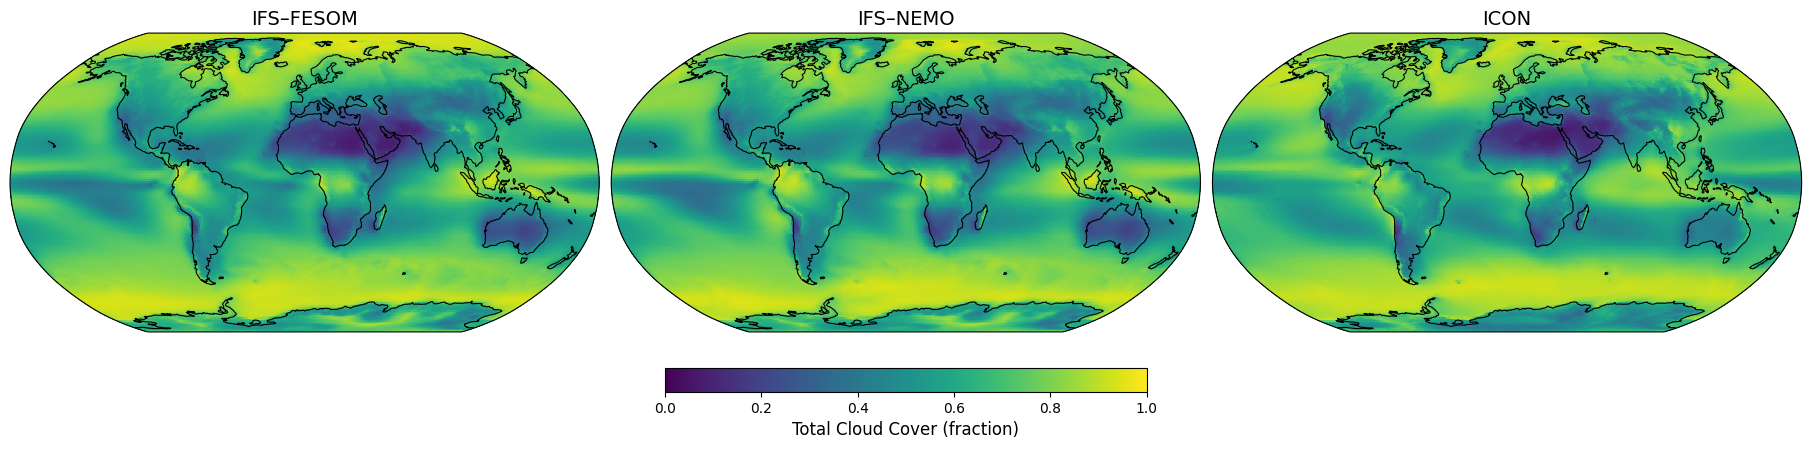

In [3]:
# Step 13: Plot multi-year mean total cloud cover (TCC) for the three models
# Purpose:
#   • Compare TCC across models
#   • Same grid, same units (fraction)
#   • Clean layout with non-overlapping shared colorbar

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# Collect datasets and titles
data = [
    multi_year_clim["IFS-FESOM"],
    multi_year_clim["IFS-NEMO"],
    multi_year_clim["ICON"]
]

titles = [
    "IFS–FESOM",
    "IFS–NEMO",
    "ICON"
]

# Color scale (robust, shared)
vmin = 0
vmax = 1  # TCC fraction ranges 0–1

# Robinson projection
proj = ccrs.Robinson()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(18, 6),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = axes.flatten()

for ax, da, title in zip(axes, data, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=14)

# Shared horizontal colorbar
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.07
)
cbar.set_label("Total Cloud Cover (fraction)", fontsize=12)

plt.show()

## ESA-CCI : cloud cover

In [1]:
# STEP 1: Load ESA-CCI CFC dataset and inspect
# Purpose:
#   • Understand variable names, dimensions, and units
#   • Check time range and lat/lon coordinates
#   • Prepare for comparison with model TCC data

import xarray as xr

# File path
esa_file = f"{ESACCI_DIR}/ESA-CCI-cfc-1982-2016_mon.nc"

# Open dataset
ds_esa = xr.open_dataset(esa_file)

# Basic dataset overview
print(ds_esa)

# List variables
print("\nVariables in ESA-CCI dataset:")
for v in ds_esa.data_vars:
    print(v)

# Inspect coordinates
print("\nCoordinates:")
for c in ds_esa.coords:
    print(f"{c}: {ds_esa[c].values[:5]} ... {ds_esa[c].values[-5:]}")

# Check time range
if "time" in ds_esa.coords:
    print("\nTime range:", ds_esa["time"].values[[0, -1]])

# Inspect main variable (replace 'cfc' with actual variable name if different)
main_var = list(ds_esa.data_vars)[0]
print(f"\n{main_var} metadata:")
print(ds_esa[main_var])

<xarray.Dataset>
Dimensions:  (time: 415, lon: 720, lat: 360)
Coordinates:
  * time     (time) datetime64[ns] 1982-01-01 1982-02-01 ... 2016-12-01
  * lon      (lon) float32 -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
  * lat      (lat) float32 -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
Data variables:
    cfc      (time, lat, lon) float32 ...
Attributes: (12/42)
    CDI:                         Climate Data Interface version 2.4.0 (https:...
    Conventions:                 CF-1.6,ACDD-1.3
    source:                      AVHRR_NOAA-7_GAC
    institution:                 Deutscher Wetterdienst
    title:                       ESA Cloud CCI Retrieval Products L3 Output File
    project:                     Climate Change Initiative - European Space A...
    ...                          ...
    comment:                     These data were produced at ESACCI as part o...
    license:                     ESA CCI Data Policy: free and open access
    cdm_data_type:            

In [13]:
# STEP 1 (ESA-CCI): Extract 1990–2014, compute annual mean and multi-year mean
# Purpose:
#   • Align ESA-CCI cloud fraction with model data (TCC)
#   • Compute annual mean for each year (1990–2014)
#   • Compute multi-year mean for plotting/Taylor analysis

import xarray as xr
import os

# File path
esa_file = f"{ESACCI_DIR}/ESA-CCI-cfc-1982-2016_mon.nc"

# Load dataset
ds_esa = xr.open_dataset(esa_file)
da_cfc = ds_esa["cfc"]

# Select period 1990–2014
da_cfc_sel = da_cfc.sel(time=slice("1990-01-01", "2014-12-31"))

# Compute annual mean per year
da_cfc_annual = da_cfc_sel.groupby("time.year").mean("time")

# Add metadata
da_cfc_annual.attrs = da_cfc.attrs.copy()
da_cfc_annual.attrs["description"] = "Annual mean cloud fraction (1990–2014) from ESA-CCI"

# Compute multi-year mean
da_cfc_multi = da_cfc_annual.mean(dim="year")
da_cfc_multi.attrs["description"] = "Multi-year mean cloud fraction (1990–2014) from ESA-CCI"

# Optional: Save annual and multi-year mean to NetCDF
out_dir = f"{EVA_DIR}/"
os.makedirs(out_dir, exist_ok=True)

# Save annual mean
da_cfc_annual.to_netcdf(os.path.join(out_dir, "ESA-CCI_cfc_annual_1990-2014.nc"))

print("Annual mean shape:", da_cfc_annual.shape)

Annual mean shape: (25, 360, 720)


In [2]:
# STEP 2 (ESA-CCI): Load annual mean and compute multi-year mean
# Purpose:
#   • Use ESA-CCI annual mean (1990–2014) to compute a single multi-year mean
#   • Ready for spatial plots and model comparison

import xarray as xr
import os

# Folder containing saved annual mean
out_dir = f"{EVA_DIR}/"
esa_annual_file = os.path.join(out_dir, "ESA-CCI_cfc_annual_1990-2014.nc")

# Load annual mean data
da_cfc_annual = xr.open_dataarray(esa_annual_file)
print("Loaded ESA-CCI annual mean data:")
print(da_cfc_annual)

# Compute multi-year mean across 'year' dimension
da_cfc_multi = da_cfc_annual.mean(dim="year")
da_cfc_multi.attrs = da_cfc_annual.attrs.copy()
da_cfc_multi.attrs["description"] = "Multi-year mean cloud fraction (1990–2014) from ESA-CCI"

# Optional: save multi-year mean
multi_file = os.path.join(out_dir, "ESA-CCI_cfc_multi_year_1990-2014.nc")
da_cfc_multi.to_netcdf(multi_file)

print("ESA-CCI multi-year mean computed and saved successfully!")
print("Multi-year mean shape:", da_cfc_multi.shape)

Loaded ESA-CCI annual mean data:
<xarray.DataArray 'cfc' (year: 25, lat: 360, lon: 720)>
[6480000 values with dtype=float32]
Coordinates:
  * lon      (lon) float32 -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
  * lat      (lat) float32 -89.75 -89.25 -88.75 -88.25 ... 88.75 89.25 89.75
  * year     (year) int64 1990 1991 1992 1993 1994 ... 2010 2011 2012 2013 2014
Attributes:
    standard_name:  cloud_area_fraction
    long_name:      cloud fraction
    units:          1
    description:    Annual mean cloud fraction (1990–2014) from ESA-CCI
ESA-CCI multi-year mean computed and saved successfully!
Multi-year mean shape: (360, 720)


In [17]:
# STEP 3 (ESA-CCI): Regrid multi-year mean to IFS-FESOM model grid
# Purpose:
#   • Use IFS-FESOM annual mean grid as reference
#   • Regrid ESA-CCI multi-year mean to match model (180x360)
#   • Ready for spatial comparison / Taylor analysis

import xarray as xr
import xesmf as xe
import os

# Paths
model_file = f"{EVA_DIR}/IFS-FESOM_tcc_annual_mean_1990-2014.nc"
esa_multi_file = f"{EVA_DIR}/ESA-CCI_cfc_multi_year_1990-2014.nc"

# Load IFS-FESOM annual mean to get model grid
da_fesom = xr.open_dataarray(model_file)
model_lat = da_fesom.lat.values
model_lon = da_fesom.lon.values

# Load ESA-CCI multi-year mean
da_cfc_multi = xr.open_dataarray(esa_multi_file)
print("ESA-CCI multi-year mean loaded, shape:", da_cfc_multi.shape)

# Create target grid dataset
ds_out = xr.Dataset(
    {
        "lat": (["lat"], model_lat),
        "lon": (["lon"], model_lon)
    }
)

# Create regridder (bilinear interpolation)
# Note: Do NOT set reuse_weights=True for the first run
regridder = xe.Regridder(da_cfc_multi, ds_out, "bilinear")

# Regrid ESA-CCI multi-year mean
da_cfc_regrid = regridder(da_cfc_multi)

# Update metadata
da_cfc_regrid.attrs = da_cfc_multi.attrs.copy()
da_cfc_regrid.attrs["description"] = "ESA-CCI CFC multi-year mean regridded to IFS-FESOM grid (180x360)"

# Check result
print("Regridded ESA-CCI shape:", da_cfc_regrid.shape)

ESA-CCI multi-year mean loaded, shape: (360, 720)
Regridded ESA-CCI shape: (180, 360)


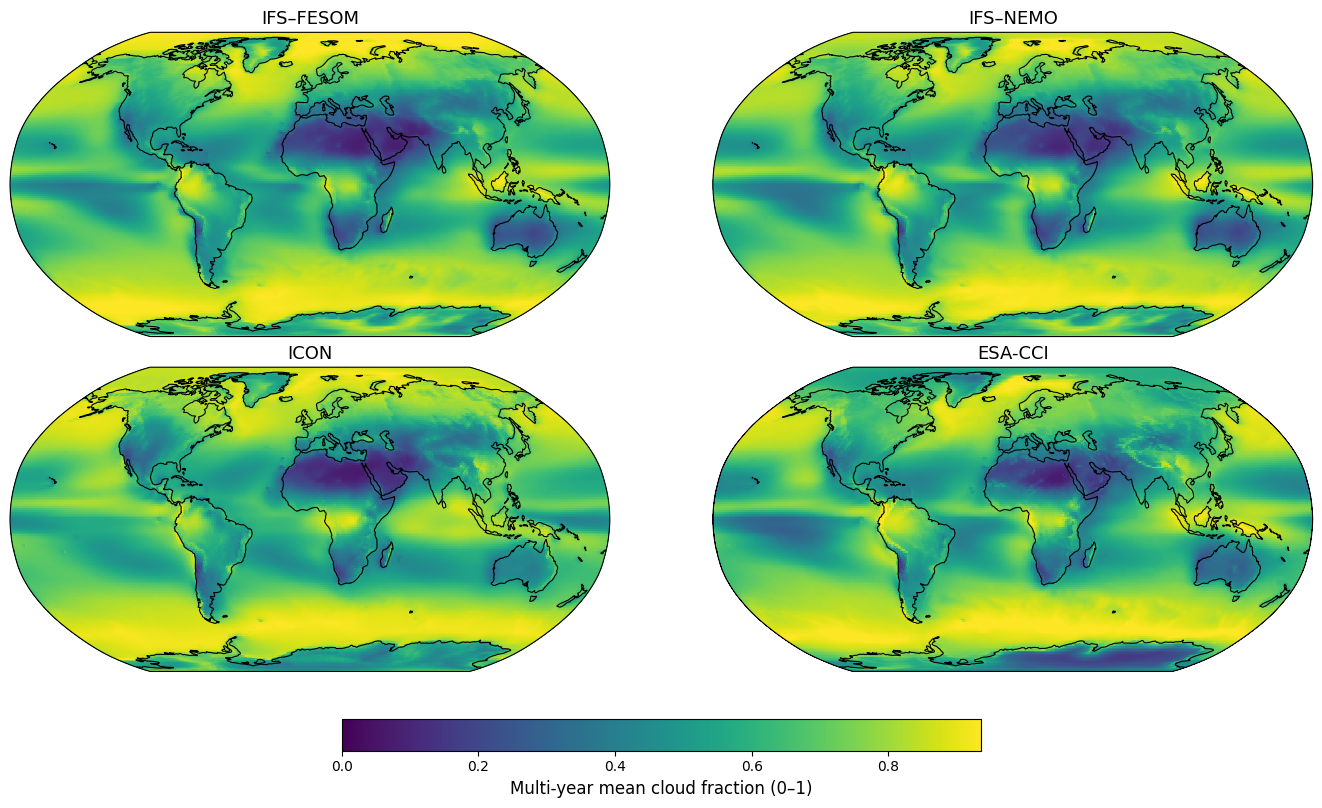

In [8]:
# Step 15: Plot multi-year mean Total Cloud Cover / Cloud Fraction for models + ESA-CCI
# Purpose:
#   • Compare cloud fraction across IFS-FESOM, IFS-NEMO, ICON, ESA-CCI
#   • Same grid, same units (fraction 0–1), shared color scale
#   • Clean layout with non-overlapping shared colorbar

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# Collect datasets and titles
data = [
    multi_year_clim["IFS-FESOM"],
    multi_year_clim["IFS-NEMO"],
    multi_year_clim["ICON"],
    da_cfc_regrid  # ESA-CCI regridded multi-year mean
]

titles = [
    "IFS–FESOM",
    "IFS–NEMO",
    "ICON",
    "ESA-CCI"
]

# Shared color scale (robust)
vmin = 0
vmax = np.percentile(
    np.concatenate([d.values.ravel() for d in data]),
    99
)

# Robinson projection for global plots
proj = ccrs.Robinson()

fig, axes = plt.subplots(
    nrows=2, ncols=2,
    figsize=(14, 8),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = axes.flatten()

for ax, da, title in zip(axes, data, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=13)

# Shared horizontal colorbar
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.07
)

cbar.set_label(
    "Multi-year mean cloud fraction (0–1)",
    fontsize=12
)

plt.show()

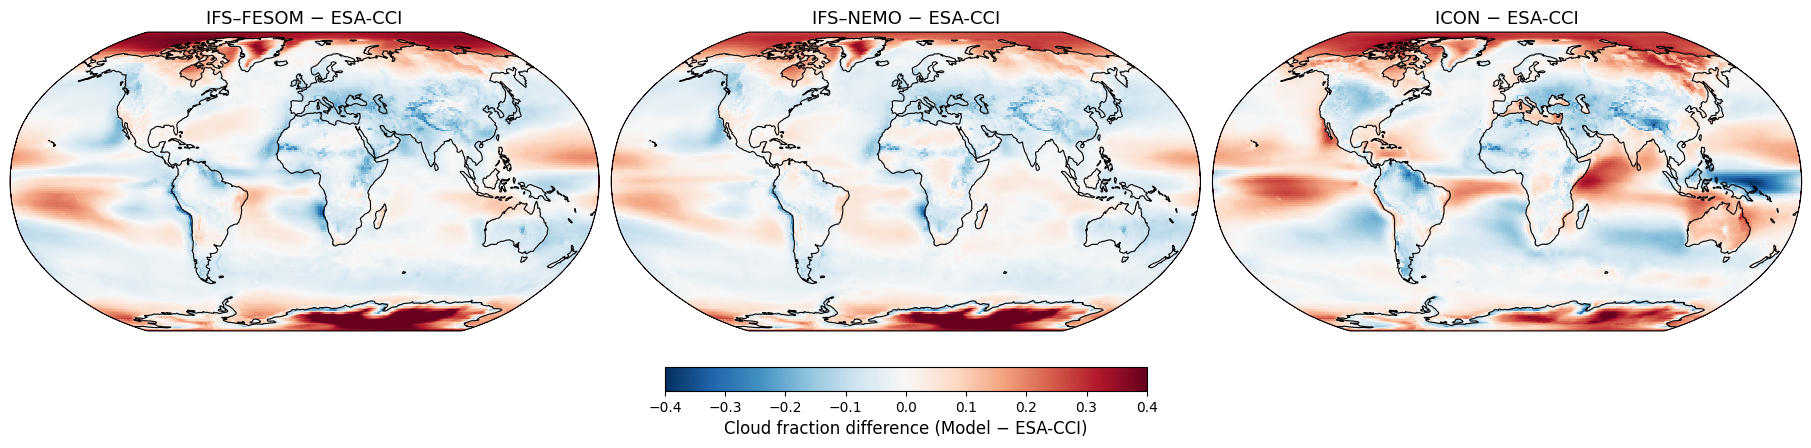

In [12]:
# Step 16: Plot difference (Model - ESA-CCI) multi-year mean cloud fraction
# Purpose:
#   • Visualize biases of each model relative to ESA-CCI
#   • Same grid, same color scale (centered at 0)
#   • One figure, 3 panels

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# Compute differences
diff_data = [
    multi_year_clim["IFS-FESOM"] - da_cfc_regrid,
    multi_year_clim["IFS-NEMO"] - da_cfc_regrid,
    multi_year_clim["ICON"] - da_cfc_regrid
]

titles = [
    "IFS–FESOM − ESA-CCI",
    "IFS–NEMO − ESA-CCI",
    "ICON − ESA-CCI"
]

# Determine a symmetric color range around 0 for differences
# vmax = np.max([np.abs(d.values).max() for d in diff_data])
# vmin = -vmax

vmax = 0.4
vmin = -0.4

proj = ccrs.Robinson()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(18, 6),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = axes.flatten()

for ax, da, title in zip(axes, diff_data, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",  # Red-Blue diverging
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=13)

# Shared horizontal colorbar
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.07
)
cbar.set_label(
    "Cloud fraction difference (Model − ESA-CCI)",
    fontsize=12
)

plt.show()

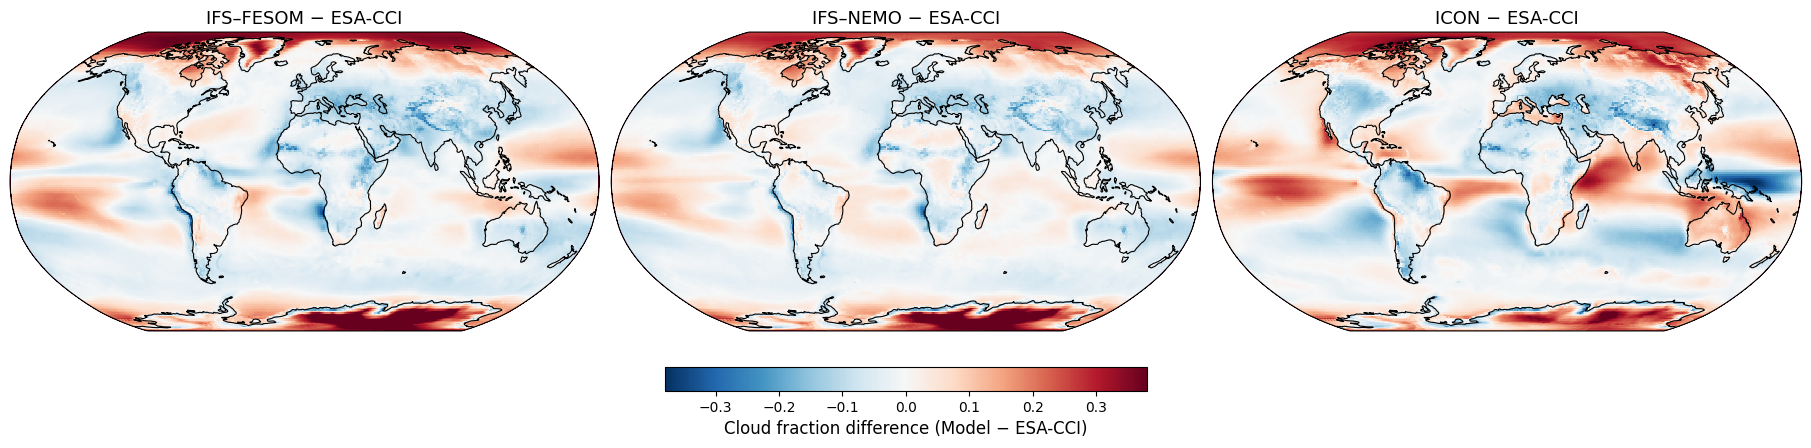

In [10]:
# Step 17: Difference plots (Model − ESA-CCI)
# Percentile-based color scaling to highlight subtle biases

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np

# Compute differences
diff_data = [
    multi_year_clim["IFS-FESOM"] - da_cfc_regrid,
    multi_year_clim["IFS-NEMO"]  - da_cfc_regrid,
    multi_year_clim["ICON"]      - da_cfc_regrid
]

titles = [
    "IFS–FESOM − ESA-CCI",
    "IFS–NEMO − ESA-CCI",
    "ICON − ESA-CCI"
]

# Stack all differences to compute robust percentiles
all_diff_vals = np.concatenate(
    [np.abs(d.values).ravel() for d in diff_data]
)

vmax = np.nanpercentile(all_diff_vals, 98)
vmin = -vmax

proj = ccrs.Robinson()

fig, axes = plt.subplots(
    nrows=1, ncols=3,
    figsize=(18, 6),
    subplot_kw={"projection": proj},
    constrained_layout=True
)

axes = axes.flatten()

for ax, da, title in zip(axes, diff_data, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=13)

# Shared colorbar
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.07
)
cbar.set_label(
    "Cloud fraction difference (Model − ESA-CCI)",
    fontsize=12
)

plt.show()

In [18]:
# STEP 12 (ESA-CCI): Regrid multi-year mean to IFS-FESOM grid and save
# Purpose:
#   • Align ESA-CCI cloud fraction with model grid (180x360)
#   • Ensure shape consistency for Taylor diagram
#   • Save regridded ESA-CCI multi-year mean for reuse

import xarray as xr
import xesmf as xe
import os

# Paths
model_file = f"{EVA_DIR}/IFS-FESOM_tcc_annual_mean_1990-2014.nc"
esa_multi_file = f"{EVA_DIR}/ESA-CCI_cfc_multi_year_1990-2014.nc"
out_dir = f"{EVA_DIR}/"
out_file = os.path.join(out_dir, "ESA-CCI_tcc_multi_year_mean_1990-2014_regrid_IFS-FESOM.nc")

# Load IFS-FESOM grid
da_fesom = xr.open_dataarray(model_file)
model_lat = da_fesom.lat.values
model_lon = da_fesom.lon.values

# Load ESA-CCI multi-year mean
da_cfc_multi = xr.open_dataarray(esa_multi_file)
print("ESA-CCI original shape:", da_cfc_multi.shape)

# Target grid
ds_out = xr.Dataset(
    {
        "lat": (["lat"], model_lat),
        "lon": (["lon"], model_lon),
    }
)

# Create regridder (first time → no reuse_weights)
regridder = xe.Regridder(
    da_cfc_multi,
    ds_out,
    method="bilinear",
    periodic=True
)

# Regrid
da_cfc_regrid = regridder(da_cfc_multi)

# Metadata
da_cfc_regrid.attrs = da_cfc_multi.attrs.copy()
da_cfc_regrid.attrs["description"] = (
    "ESA-CCI cloud fraction multi-year mean (1990–2014) "
    "regridded to IFS-FESOM grid (180x360)"
)

# Save
da_cfc_regrid.to_netcdf(out_file)

print("Regridded ESA-CCI shape:", da_cfc_regrid.shape)
print("Saved to:", out_file)

ESA-CCI original shape: (360, 720)
Regridded ESA-CCI shape: (180, 360)
Saved to: <EVA_DIR>/ESA-CCI_tcc_multi_year_mean_1990-2014_regrid_IFS-FESOM.nc


## Taylor Plot

In [19]:
# STEP X: Compute & save multi-year mean TCC (models + ESA-CCI)
# Purpose:
#   • Collapse annual mean climatologies (1990–2014) into a single field
#   • Save one multi-year mean per dataset
#   • Prepare consistent inputs for regridding and Taylor analysis

import os
import xarray as xr

# Folder containing annual climatologies
clim_dir = f"{EVA_DIR}/"

# Models
models = ["IFS-FESOM", "IFS-NEMO", "ICON"]

# Optional container for later use
multi_year_clim = {}

# =====================
# MODELS
# =====================
for model in models:
    infile = os.path.join(
        clim_dir, f"{model}_tcc_annual_mean_1990-2014.nc"
    )
    outfile = os.path.join(
        clim_dir, f"{model}_tcc_multi_year_mean_1990-2014.nc"
    )

    # Load annual mean climatology
    ds = xr.open_dataset(infile)

    # Assume single variable (TCC)
    varname = list(ds.data_vars)[0]
    da = ds[varname]

    # Multi-year mean
    da_mean = da.mean(dim="year")

    # Metadata
    da_mean.attrs = da.attrs.copy()
    da_mean.attrs["description"] = (
        f"Multi-year mean total cloud cover (1990–2014) from {model}"
    )

    # Save
    da_mean.to_netcdf(outfile)

    multi_year_clim[model] = da_mean

    print(f"{model}: multi-year mean saved → {outfile}")

# =====================
# ESA-CCI
# =====================
esa_in = os.path.join(
    clim_dir, "ESA-CCI_cfc_multi_year_1990-2014.nc"
)
esa_out = os.path.join(
    clim_dir, "ESA-CCI_tcc_multi_year_mean_1990-2014.nc"
)

# Load ESA-CCI multi-year mean
ds_esa = xr.open_dataset(esa_in)
varname = list(ds_esa.data_vars)[0]
da_esa = ds_esa[varname]

# Metadata cleanup
da_esa.attrs["description"] = (
    "ESA-CCI multi-year mean cloud fraction (1990–2014)"
)

# Save
da_esa.to_netcdf(esa_out)

multi_year_clim["ESA-CCI"] = da_esa

print(f"ESA-CCI: multi-year mean saved → {esa_out}")

IFS-FESOM: multi-year mean saved → <EVA_DIR>/IFS-FESOM_tcc_multi_year_mean_1990-2014.nc
IFS-NEMO: multi-year mean saved → <EVA_DIR>/IFS-NEMO_tcc_multi_year_mean_1990-2014.nc
ICON: multi-year mean saved → <EVA_DIR>/ICON_tcc_multi_year_mean_1990-2014.nc
ESA-CCI: multi-year mean saved → <EVA_DIR>/ESA-CCI_tcc_multi_year_mean_1990-2014.nc


In [21]:
# STEP X+1: Load & verify multi-year mean TCC fields (models + ESA-CCI)
# Purpose:
#   • Load final multi-year mean datasets
#   • Ensure common grid (lat, lon)
#   • Verify units and missing values
#   • Prepare inputs for Taylor diagram statistics

import os
import xarray as xr
import numpy as np

clim_dir = f"{EVA_DIR}/"

files = {
    "IFS-FESOM": "IFS-FESOM_tcc_multi_year_mean_1990-2014.nc",
    "IFS-NEMO":  "IFS-NEMO_tcc_multi_year_mean_1990-2014.nc",
    "ICON":     "ICON_tcc_multi_year_mean_1990-2014.nc",
    "ESA-CCI":  "ESA-CCI_tcc_multi_year_mean_1990-2014_regrid_IFS-FESOM.nc",
}

multi_year_loaded = {}

for name, fname in files.items():
    path = os.path.join(clim_dir, fname)
    ds = xr.open_dataset(path)

    # Assume single variable
    varname = list(ds.data_vars)[0]
    da = ds[varname]

    multi_year_loaded[name] = da

    # ---- Diagnostics ----
    print(f"\n{name}")
    print("-" * len(name))
    print(f"Shape        : {da.shape}")
    print(f"Dimensions   : {da.dims}")
    print(
        f"Lat range    : {float(da.lat.min()):.2f} → {float(da.lat.max()):.2f}"
    )
    print(
        f"Lon range    : {float(da.lon.min()):.2f} → {float(da.lon.max()):.2f}"
    )
    print(f"Units        : {da.attrs.get('units', 'N/A')}")
    print(f"Missing vals : {np.isnan(da.values).sum()}")

print("\n✅ All multi-year mean datasets loaded and verified.")


IFS-FESOM
---------
Shape        : (180, 360)
Dimensions   : ('lat', 'lon')
Lat range    : -89.50 → 89.50
Lon range    : 0.00 → 359.00
Units        : 1
Missing vals : 0

IFS-NEMO
--------
Shape        : (180, 360)
Dimensions   : ('lat', 'lon')
Lat range    : -89.50 → 89.50
Lon range    : 0.00 → 359.00
Units        : 1
Missing vals : 0

ICON
----
Shape        : (180, 360)
Dimensions   : ('lat', 'lon')
Lat range    : -89.50 → 89.50
Lon range    : 0.00 → 359.00
Units        : 1
Missing vals : 0

ESA-CCI
-------
Shape        : (180, 360)
Dimensions   : ('lat', 'lon')
Lat range    : -89.50 → 89.50
Lon range    : 0.00 → 359.00
Units        : 1
Missing vals : 0

✅ All multi-year mean datasets loaded and verified.


In [22]:
# STEP: Compute Taylor statistics (std, correlation, RMSD)
# Purpose:
#   • Prepare inputs for Taylor diagram
#   • Use ESA-CCI as reference
#   • Compute spatial statistics on flattened global fields

import numpy as np

# Reference field (ESA-CCI)
ref = multi_year_loaded["ESA-CCI"].values.flatten()

# Remove any potential NaNs (safe guard)
valid = np.isfinite(ref)

ref = ref[valid]
ref_std = np.std(ref, ddof=1)

print(f"Reference (ESA-CCI) std = {ref_std:.4f}")

# Containers for Taylor stats
taylor_stats = {}

for model in ["IFS-FESOM", "IFS-NEMO", "ICON"]:
    mod = multi_year_loaded[model].values.flatten()
    mod = mod[valid]

    # Standard deviation
    mod_std = np.std(mod, ddof=1)

    # Correlation
    corr = np.corrcoef(ref, mod)[0, 1]

    # Centered RMS difference
    crmsd = np.sqrt(
        np.mean(
            ((mod - mod.mean()) - (ref - ref.mean()))**2
        )
    )

    taylor_stats[model] = {
        "std": mod_std,
        "corr": corr,
        "crmsd": crmsd,
    }

    print(f"\n{model}")
    print(f"  Std dev      : {mod_std:.4f}")
    print(f"  Correlation  : {corr:.4f}")
    print(f"  Centered RMS : {crmsd:.4f}")

Reference (ESA-CCI) std = 0.1835

IFS-FESOM
  Std dev      : 0.1835
  Correlation  : 0.7084
  Centered RMS : 0.1401

IFS-NEMO
  Std dev      : 0.1746
  Correlation  : 0.7604
  Centered RMS : 0.1242

ICON
  Std dev      : 0.1767
  Correlation  : 0.7754
  Centered RMS : 0.1209


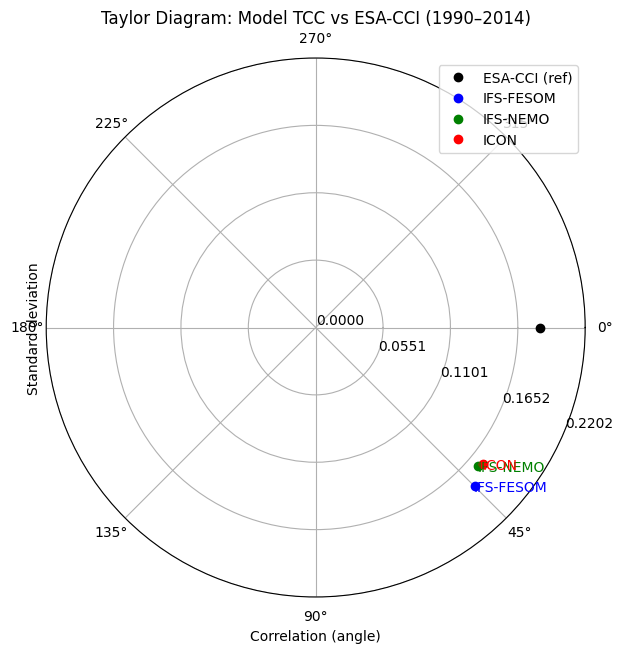

In [23]:
# STEP: Plot Taylor diagram for TCC (models vs ESA-CCI)
# Purpose:
#   • Visualize spatial agreement of models with ESA-CCI
#   • Show correlation, std dev, and centered RMS

import matplotlib.pyplot as plt
import numpy as np

# Function to convert correlation to angle in radians
def corr_to_angle(corr):
    return np.arccos(corr)

# Reference std
ref_std = taylor_stats["IFS-FESOM"]["std"]  # ESA-CCI used as reference

# Models to plot
models = ["IFS-FESOM", "IFS-NEMO", "ICON"]
colors = ["blue", "green", "red"]

# Create figure
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(111, polar=True)

# Plot reference point
ax.plot(0, ref_std, 'ko', label="ESA-CCI (ref)")

# Plot each model
for model, color in zip(models, colors):
    stats = taylor_stats[model]
    angle = corr_to_angle(stats["corr"])
    std = stats["std"]
    ax.plot(angle, std, 'o', color=color, label=model)
    # optional: add labels
    ax.text(angle + 0.02, std + 0.002, model, color=color, fontsize=10)

# Customize polar plot
ax.set_theta_zero_location("E")      # 0 deg at right
ax.set_theta_direction(-1)           # clockwise
ax.set_rmax(max([taylor_stats[m]["std"] for m in models] + [ref_std]) * 1.2)
ax.set_rticks(np.linspace(0, ax.get_rmax(), 5))
ax.set_xlabel("Correlation (angle)")
ax.set_ylabel("Standard deviation")

# Add legend
ax.legend(loc="upper right")

# Title
plt.title("Taylor Diagram: Model TCC vs ESA-CCI (1990–2014)", fontsize=12)

plt.show()

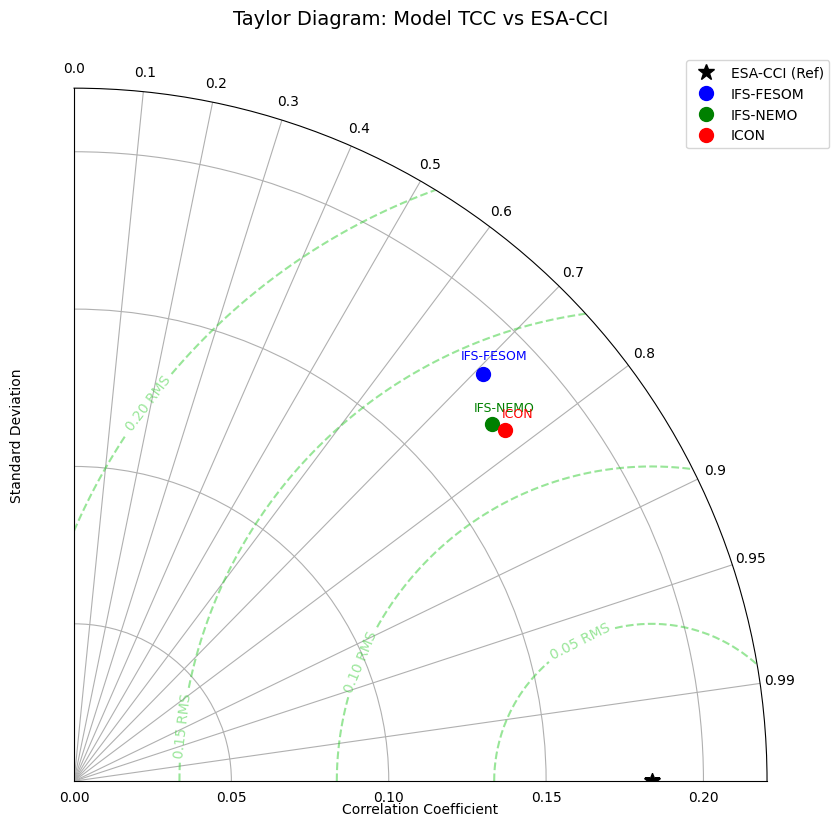

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. REAL DATA INPUT ---
# Reference standard deviation (ESA-CCI)
ref_std = 0.1835

# Model statistics dictionary
taylor_stats = {
    "IFS-FESOM": {"std": 0.1835, "corr": 0.7084},
    "IFS-NEMO":  {"std": 0.1746, "corr": 0.7604},
    "ICON":      {"std": 0.1767, "corr": 0.7754}
}

models = ["IFS-FESOM", "IFS-NEMO", "ICON"]
colors = ["blue", "green", "red"]

# Function to convert correlation to angle in radians
def corr_to_angle(corr):
    return np.arccos(corr)

# --- 2. PLOT SETUP ---
fig = plt.figure(figsize=(9, 9))
# polar=True enables the radial coordinate system
ax = fig.add_subplot(111, polar=True)

# Set 0 degrees to East (standard math convention)
ax.set_theta_zero_location("E") 

# Limit plot to 1st Quadrant (Correlation 0 to 1)
ax.set_thetamin(0)
ax.set_thetamax(90)

# Determine radial limit (Max Std Dev * padding)
# We check all models + reference to ensure nothing is cut off
all_stds = [taylor_stats[m]["std"] for m in models] + [ref_std]
max_plot_std = max(all_stds) * 1.2
ax.set_rmax(max_plot_std)

# --- 3. CUSTOM GRID & LABELS ---

# A. Correlation Axis (Angular)
# We plot specific correlation ticks, then label them
correlations = [0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0.0]
angles = np.arccos(correlations)
ax.set_xticks(angles)
ax.set_xticklabels([str(c) for c in correlations])
ax.set_xlabel("Correlation Coefficient", labelpad=15)

# B. Standard Deviation Axis (Radial)
# Create nice round numbers for the radial grid based on your data range (0 to ~0.2)
ax.set_ylabel("Standard Deviation", labelpad=25)
# Set radial ticks (e.g., 0.05, 0.10, 0.15, 0.20)
rticks = np.arange(0, max_plot_std, 0.05)
ax.set_rticks(rticks)
ax.set_yticklabels([f"{x:.2f}" for x in rticks])

# --- 4. RMS CONTOURS (Green Dashed Lines) ---
# Grid for calculating RMS distance from the Reference Point
# Law of Cosines: RMS^2 = r^2 + ref^2 - 2*r*ref*cos(theta)
r_grid, theta_grid = np.meshgrid(
    np.linspace(0, max_plot_std, 100),
    np.linspace(0, np.pi/2, 100)
)
rms_grid = np.sqrt(r_grid**2 + ref_std**2 - 2*r_grid*ref_std*np.cos(theta_grid))

# Draw contours at specific RMS levels (e.g., 0.05, 0.1, 0.15)
contours = ax.contour(
    theta_grid, r_grid, rms_grid, 
    levels=np.arange(0.05, 0.25, 0.05),  # Adjust levels based on your data scale
    colors='limegreen', 
    alpha=0.5, 
    linestyles='--'
)
ax.clabel(contours, inline=1, fontsize=10, fmt='%.2f RMS')

# --- 5. PLOTTING THE POINTS ---

# Plot Reference Point (Correlation=1.0, Std=ref_std)
# Angle is 0 because arccos(1) = 0
ax.plot(0, ref_std, 'k*', ms=12, label="ESA-CCI (Ref)", zorder=5)

# Plot Models
for model, color in zip(models, colors):
    stats = taylor_stats[model]
    angle = corr_to_angle(stats["corr"])
    std = stats["std"]
    
    ax.plot(angle, std, 'o', color=color, label=model, ms=10, zorder=5)
    
    # Optional: Add text label near the point
    # Offset text slightly for readability
    ax.text(angle, std + 0.005, model, color=color, fontsize=9, ha='center', va='bottom')

# --- 6. LEGEND & TITLE ---
# Place legend outside to keep the diagram clean
ax.legend(bbox_to_anchor=(1.1, 1.05), loc="upper right")

plt.title("Taylor Diagram: Model TCC vs ESA-CCI", y=1.08, fontsize=14)

plt.show()

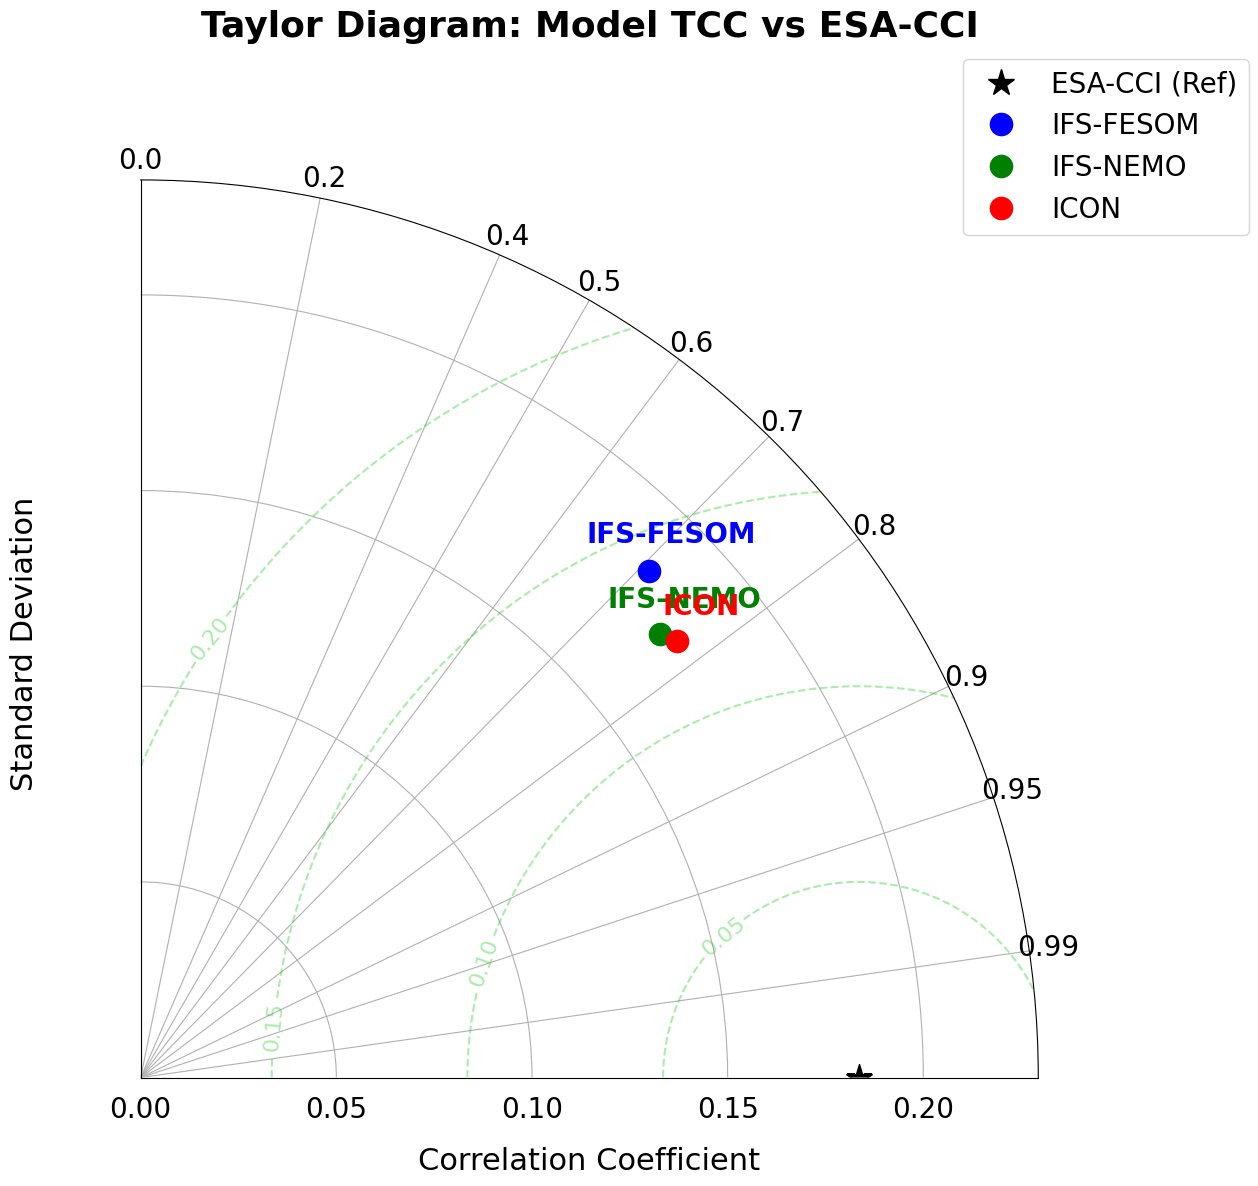

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. REAL DATA INPUT ---
ref_std = 0.1835

taylor_stats = {
    "IFS-FESOM": {"std": 0.1835, "corr": 0.7084},
    "IFS-NEMO":  {"std": 0.1746, "corr": 0.7604},
    "ICON":      {"std": 0.1767, "corr": 0.7754}
}

models = ["IFS-FESOM", "IFS-NEMO", "ICON"]
colors = ["blue", "green", "red"]

def corr_to_angle(corr):
    return np.arccos(corr)

# --- 2. PLOT SETUP ---
# CRANKED UP FONT SIZES
LABEL_FONT = 22
TITLE_FONT = 26
TICK_FONT = 20  # This controls the numbers on the axes

fig = plt.figure(figsize=(14, 12))
ax = fig.add_subplot(111, polar=True)

ax.set_theta_zero_location("E") 
ax.set_thetamin(0)
ax.set_thetamax(90)

all_stds = [taylor_stats[m]["std"] for m in models] + [ref_std]
max_plot_std = max(all_stds) * 1.25
ax.set_rmax(max_plot_std)

# --- 3. CUSTOM GRID & LABELS ---

# A. Correlation Axis (The outer arc)
correlations = np.array([0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.2, 0.0])
angles = np.arccos(correlations)
ax.set_xticks(angles)
ax.set_xticklabels([str(c) for c in correlations], fontsize=TICK_FONT)
ax.set_xlabel("Correlation Coefficient", fontsize=LABEL_FONT, labelpad=50)

# B. Standard Deviation Axis (The horizontal values you requested)
rticks = np.arange(0, max_plot_std, 0.05)
ax.set_rticks(rticks)
# Use tick_params to ensure the radial labels (Std Dev) are large
ax.tick_params(axis='y', labelsize=TICK_FONT, pad=10) 
ax.set_yticklabels([f"{x:.2f}" for x in rticks])

# Move the "Standard Deviation" title further left so it doesn't hit the large numbers
ax.text(np.deg2rad(105), max_plot_std/2, "Standard Deviation", 
        fontsize=LABEL_FONT, rotation=90, ha='center', va='center')

# --- 4. RMS CONTOURS ---
r_grid, theta_grid = np.meshgrid(
    np.linspace(0, max_plot_std, 100),
    np.linspace(0, np.pi/2, 100)
)
rms_grid = np.sqrt(r_grid**2 + ref_std**2 - 2*r_grid*ref_std*np.cos(theta_grid))

contours = ax.contour(
    theta_grid, r_grid, rms_grid, 
    levels=np.arange(0.05, 0.25, 0.05),
    colors='limegreen', 
    alpha=0.4, 
    linestyles='--'
)
ax.clabel(contours, inline=1, fontsize=TICK_FONT-4, fmt='%.2f')

# --- 5. PLOTTING THE POINTS ---
ax.plot(0, ref_std, 'k*', ms=20, label="ESA-CCI (Ref)", zorder=10)

for model, color in zip(models, colors):
    stats = taylor_stats[model]
    angle = corr_to_angle(stats["corr"])
    std = stats["std"]
    
    ax.plot(angle, std, 'o', color=color, label=model, ms=16, zorder=10)
    ax.text(angle, std + 0.008, model, color=color, 
            fontsize=TICK_FONT, fontweight='bold', ha='center', va='bottom')

# --- 6. LEGEND & TITLE ---
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.15), fontsize=TICK_FONT, frameon=True)
plt.title("Taylor Diagram: Model TCC vs ESA-CCI", y=1.15, fontsize=TITLE_FONT, fontweight='bold')

plt.tight_layout()
plt.show()

## Trends

In [6]:
# Load saved annual mean TCC files and inspect

import xarray as xr
import os

# Folder containing saved annual mean climatologies
clim_dir = f"{EVA_DIR}/"

# Models
models = ["IFS-FESOM", "IFS-NEMO", "ICON"]

# Dictionary to store loaded datasets
annual_clim_loaded = {}

for model in models:
    file_path = os.path.join(clim_dir, f"{model}_tcc_annual_mean_1990-2014.nc")
    
    # Load NetCDF (annual mean for each year)
    da = xr.open_dataarray(file_path)
    
    # Inspect basic info
    print(f"\nModel: {model}")
    print(da)
    
    # Check dimensions and coordinates
    print("Dimensions:", da.dims)
    print("Coordinates:")
    for c in da.coords:
        print(f"  {c}: {da[c].values[:5]} ... {da[c].values[-5:]}")
    
    # Store in dictionary for later use
    annual_clim_loaded[model] = da


Model: IFS-FESOM
<xarray.DataArray 'tcc' (year: 25, lat: 180, lon: 360)>
[1620000 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
  * year     (year) int64 1990 1991 1992 1993 1994 ... 2010 2011 2012 2013 2014
Attributes:
    units:        1
    description:  Annual mean TCC (1990-2014) from IFS-FESOM
Dimensions: ('year', 'lat', 'lon')
Coordinates:
  lat: [-89.5 -88.5 -87.5 -86.5 -85.5] ... [85.5 86.5 87.5 88.5 89.5]
  lon: [0. 1. 2. 3. 4.] ... [355. 356. 357. 358. 359.]
  year: [1990 1991 1992 1993 1994] ... [2010 2011 2012 2013 2014]

Model: IFS-NEMO
<xarray.DataArray 'tcc' (year: 25, lat: 180, lon: 360)>
[1620000 values with dtype=float64]
Coordinates:
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
  * year     (year)

In [2]:
# STEP 2: Regrid ESA-CCI annual mean (1990-2014) to IFS-FESOM grid & Save

# # (not required for futureas the file is now savedto the directory)

# Purpose:
#   • Align ESA-CCI annual mean cloud fraction with model grid (180x360)
#   • Ensure consistency for computing trends and Taylor diagrams
#   • Save regridded annual mean for reuse

import xarray as xr
import xesmf as xe
import os

# Paths
model_file = f"{EVA_DIR}/IFS-FESOM_tcc_annual_mean_1990-2014.nc"
esa_annual_file = f"{EVA_DIR}/ESA-CCI_cfc_annual_1990-2014.nc"
out_dir = f"{EVA_DIR}/"
out_file = os.path.join(out_dir, "ESA-CCI_cfc_annual_mean_1990-2014_regrid_IFS-FESOM.nc")

# Load IFS-FESOM annual mean to get model grid
da_fesom = xr.open_dataarray(model_file)
model_lat = da_fesom.lat.values
model_lon = da_fesom.lon.values

# Load ESA-CCI annual mean (shape: 25, 360, 720)
da_esa = xr.open_dataarray(esa_annual_file)
print("Original ESA-CCI annual mean shape:", da_esa.shape)

# Create target grid dataset
ds_out = xr.Dataset(
    {
        "lat": (["lat"], model_lat),
        "lon": (["lon"], model_lon)
    }
)

# Create regridder (bilinear interpolation, periodic in longitude)
regridder = xe.Regridder(da_esa, ds_out, method="bilinear", periodic=True)

# Regrid ESA-CCI annual mean
da_esa_regrid = regridder(da_esa)

# Update metadata
da_esa_regrid.attrs = da_esa.attrs.copy()
da_esa_regrid.attrs["description"] = (
    "ESA-CCI annual mean cloud fraction (1990–2014) regridded to IFS-FESOM grid (180x360)"
)

# Save regridded annual mean
da_esa_regrid.to_netcdf(out_file)

print("Regridded ESA-CCI annual mean shape:", da_esa_regrid.shape)
print("Saved to:", out_file)

Original ESA-CCI annual mean shape: (25, 360, 720)
Regridded ESA-CCI annual mean shape: (25, 180, 360)
Saved to: <EVA_DIR>/ESA-CCI_cfc_annual_mean_1990-2014_regrid_IFS-FESOM.nc


In [7]:
# STEP 3: Load ESA-CCI regridded annual mean and compute trends for all datasets
# (not required for futureas the file is now savedto the directory

# Purpose:
#   • Align ESA-CCI annual mean with model grids
#   • Compute linear trend at each grid point (TCC / cloud fraction)
#   • Trends ready for plotting maps or further analysis

import xarray as xr
import numpy as np
from scipy.stats import linregress
import os

# Paths
esa_file = f"{EVA_DIR}/ESA-CCI_cfc_annual_mean_1990-2014_regrid_IFS-FESOM.nc"

# Load ESA-CCI regridded annual mean
da_esa = xr.open_dataarray(esa_file)
print("ESA-CCI regridded annual mean shape:", da_esa.shape)

# Assume model datasets are already loaded in a dictionary 'annual_clim_loaded'
# Keys: "IFS-FESOM", "IFS-NEMO", "ICON"
# Add ESA-CCI
annual_clim_loaded["ESA-CCI"] = da_esa

# Compute linear trend at each grid point
def compute_trend(da):
    """
    Compute linear trend (slope per year) for a 3D xarray.DataArray (year, lat, lon)
    Returns a 2D array of slopes: (lat, lon)
    """
    years = da.year.values if "year" in da.coords else np.arange(da.shape[0])
    trend = np.full((da.lat.size, da.lon.size), np.nan, dtype=np.float32)

    for i in range(da.lat.size):
        for j in range(da.lon.size):
            y = da[:, i, j].values
            if np.all(np.isfinite(y)):
                slope, _, _, _, _ = linregress(years, y)
                trend[i, j] = slope
    return xr.DataArray(
        trend,
        coords={"lat": da.lat, "lon": da.lon},
        dims=["lat", "lon"],
        attrs={"units": "1/year", "description": "Linear trend of TCC / cloud fraction per year"}
    )

# Dictionary to store trends
trend_clim = {}

for model, da in annual_clim_loaded.items():
    trend_da = compute_trend(da)
    trend_clim[model] = trend_da
    print(f"{model}: trend computed, shape = {trend_da.shape}")

ESA-CCI regridded annual mean shape: (25, 180, 360)
IFS-FESOM: trend computed, shape = (180, 360)
IFS-NEMO: trend computed, shape = (180, 360)
ICON: trend computed, shape = (180, 360)
ESA-CCI: trend computed, shape = (180, 360)


In [37]:
# STEP 4: Save all computed trends (models + ESA-CCI) into one NetCDF
# Purpose:
#   • Store linear trends of TCC / cloud fraction for all datasets
#   • Include metadata for clarity
#   • Ready for plotting / further analysis

import xarray as xr
import os

# Output file
out_dir = f"{EVA_DIR}/"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, "TCC_trends_1990-2014_models_ESA-CCI.nc")

# Combine all trend DataArrays into one Dataset
ds_trends = xr.Dataset(
    {model.replace("-", "_"): da for model, da in trend_clim.items()}
)

# Add global attributes
ds_trends.attrs["title"] = "Linear trends of total cloud cover (TCC) / cloud fraction (1990-2014)"
ds_trends.attrs["source"] = "IFS-FESOM, IFS-NEMO, ICON, ESA-CCI regridded"
ds_trends.attrs["description"] = "Linear trends computed at each grid point (slope per year)"
ds_trends.attrs["units"] = "1/year"

# Add variable-level metadata (optional, already in DataArrays)
for var in ds_trends.data_vars:
    ds_trends[var].attrs["long_name"] = f"Linear trend of {var} per year"

# Save to NetCDF
ds_trends.to_netcdf(out_file)

print(f"All trends saved successfully to:\n{out_file}")

All trends saved successfully to:
<EVA_DIR>/TCC_trends_1990-2014_models_ESA-CCI.nc


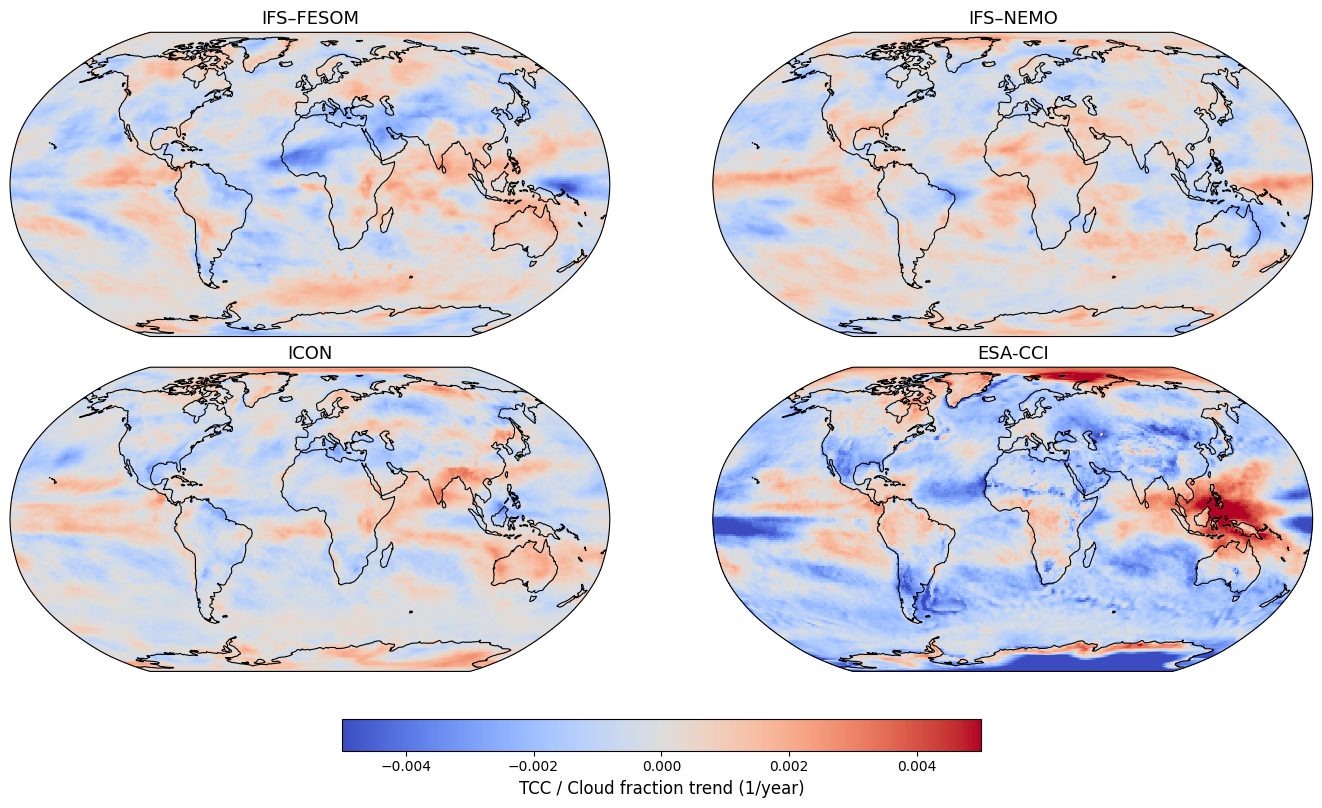

In [8]:
# STEP 5: Plot TCC / cloud fraction trends for models + ESA-CCI
# Purpose:
#   • Visualize spatial distribution of trends (1990-2014)
#   • 2x2 panel, same color scale
#   • Clean layout with shared colorbar

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import os

# Load saved trends
trend_file = f"{EVA_DIR}/TCC_trends_1990-2014_models_ESA-CCI.nc"
ds_trends = xr.open_dataset(trend_file)

# List of datasets and titles
data = [
    ds_trends["IFS_FESOM"],
    ds_trends["IFS_NEMO"],
    ds_trends["ICON"],
    ds_trends["ESA_CCI"]
]

titles = [
    "IFS–FESOM",
    "IFS–NEMO",
    "ICON",
    "ESA-CCI"
]

# Define shared color scale (robust, ignore outliers)
vmin = min([np.nanmin(d.values) for d in data])
vmax = max([np.nanmax(d.values) for d in data])
absmax = max(abs(vmin), abs(vmax))
#vmin, vmax = -absmax, absmax  # symmetric around zero for trends
vmin, vmax = -0.005, 0.005  # symmetric around zero for trends

# Projection
proj = ccrs.Robinson()

# Create figure
fig, axes = plt.subplots(
    nrows=2, ncols=2,
    figsize=(14, 8),
    subplot_kw={"projection": proj},
    constrained_layout=True
)
axes = axes.flatten()

# Plot each dataset
for ax, da, title in zip(axes, data, titles):
    im = da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap="coolwarm",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False
    )
    ax.coastlines(linewidth=0.8)
    ax.set_title(title, fontsize=13)

# Shared colorbar at the bottom
cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.07
)
cbar.set_label("TCC / Cloud fraction trend (1/year)", fontsize=12)

plt.show()

# Error

In [2]:
import xarray as xr

path = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/thetao_o00i_r100_monthly_1990.nc"

ds = xr.open_dataset(path)

print(ds)

<xarray.Dataset>
Dimensions:    (time: 12, level: 69, lat: 180, lon: 360)
Coordinates:
  * level      (level) float64 2.5 7.5 12.5 ... 5.525e+03 5.825e+03 6.175e+03
    idx_level  (level) int64 ...
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
Data variables:
    thetao     (time, level, lat, lon) float64 ...


In [2]:
import xarray as xr
clim_temp = xr.open_dataset(f'{FESOM_DATA_ROOT}/climatology_EN4_1985/ng5/temp_healpix_128_7.nc')
print(clim_temp)

<xarray.Dataset>
Dimensions:  (depth: 69, ncells: 196608, lon: 196608, lat: 196608)
Coordinates:
  * depth    (depth) float64 2.5 7.5 12.5 17.5 ... 5.525e+03 5.825e+03 6.175e+03
  * lon      (lon) float64 45.0 45.35 44.65 45.0 ... 315.0 315.4 314.6 315.0
  * lat      (lat) float64 0.2984 0.5968 0.5968 ... -0.5968 -0.5968 -0.2984
Dimensions without coordinates: ncells
Data variables:
    temp     (depth, ncells) float64 ...
Attributes:
    climatology:    EN4_1985
    zoom:           7
    nside:          128
    original_mesh:  NG5


In [3]:
import xarray as xr
from pathlib import Path

file = Path(f"{EN4_DIR}/extracted/EN.4.2.2.f.analysis.g10.200408.nc")

# File size
size_mb = file.stat().st_size / 1024**2
print(f"File size: {size_mb:.2f} MB")

# Open dataset
ds = xr.open_dataset(file)

print(ds)

File size: 25.21 MB
<xarray.Dataset>
Dimensions:                          (depth: 42, lat: 173, lon: 360, time: 1,
                                      bnds: 2)
Coordinates:
  * depth                            (depth) float32 5.022 15.08 ... 5.35e+03
  * lat                              (lat) float32 -83.0 -82.0 ... 88.0 89.0
  * lon                              (lon) float32 1.0 2.0 3.0 ... 359.0 360.0
  * time                             (time) datetime64[ns] 2004-08-16T12:00:00
Dimensions without coordinates: bnds
Data variables:
    temperature                      (time, depth, lat, lon) float32 ...
    salinity                         (time, depth, lat, lon) float32 ...
    temperature_uncertainty          (time, depth, lat, lon) float32 ...
    salinity_uncertainty             (time, depth, lat, lon) float32 ...
    temperature_observation_weights  (time, depth, lat, lon) float32 ...
    salinity_observation_weights     (time, depth, lat, lon) float32 ...
    time_bnds        